#### Initial setup, import ecessary libraries, and dataset loading

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set visual styling for publication-ready charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# 1. Load Dataset
df = pd.read_csv("ai_student_impact_dataset.csv")

print("--- Dataset Overview ---")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nBasic Summary Statistics:")
display(df.describe(include=["number"]))

--- Dataset Overview ---
Total Rows: 50000, Total Columns: 16

Missing Values per Column:
Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

Basic Summary Statistics:


,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


#### EDA with Correlation Matrix & Major Disparities

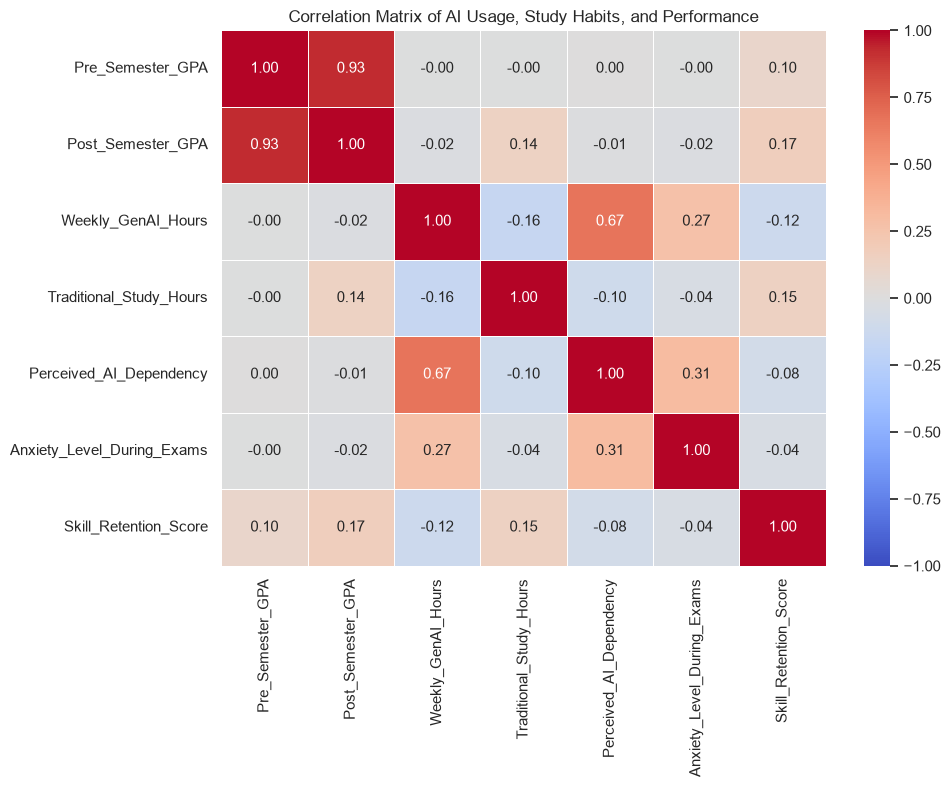

C:\Users\cecil\AppData\Local\Temp\ipykernel_18052\2346552348.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\cecil\AppData\Local\Temp\ipykernel_18052\2346552348.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


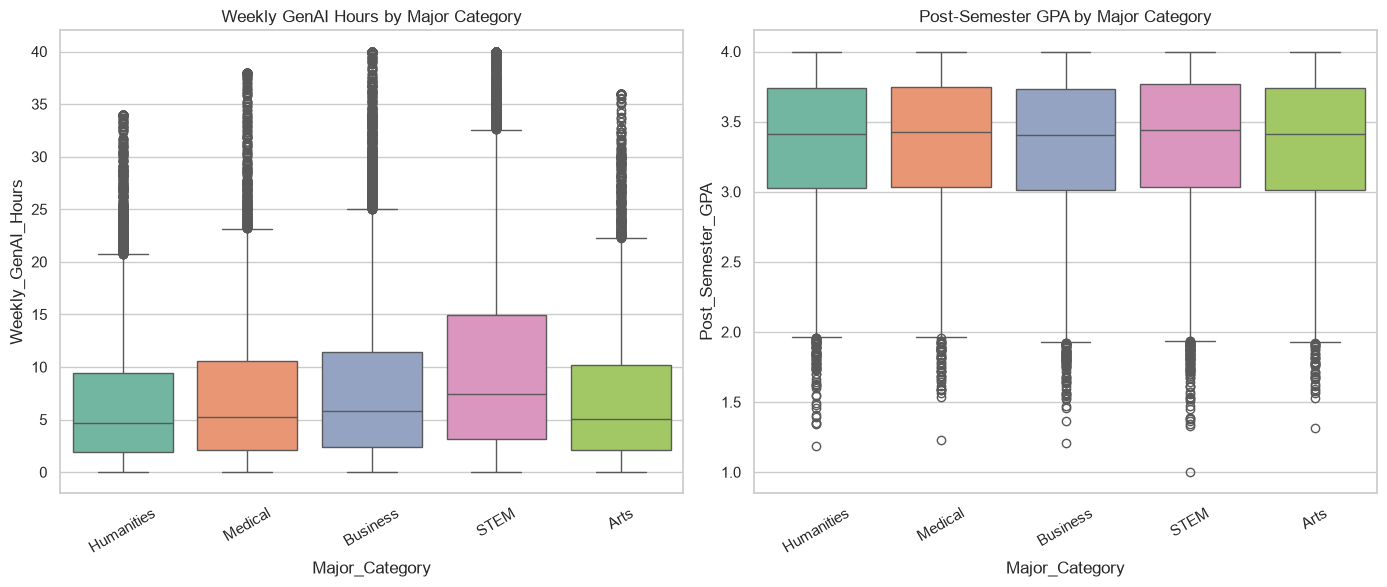

In [33]:
# Correlation Matrix & Heatmap (Numerical Features)
plt.figure(figsize=(10, 8))
num_cols = [
    "Pre_Semester_GPA",
    "Post_Semester_GPA",
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
    "Skill_Retention_Score",
]

corr_matrix = df[num_cols].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Matrix of AI Usage, Study Habits, and Performance")
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

# 3. Major Disparities Analysis (Categorical vs. Continuous)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=df,
    x="Major_Category",
    y="Weekly_GenAI_Hours",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Weekly GenAI Hours by Major Category")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=df,
    x="Major_Category",
    y="Post_Semester_GPA",
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Post-Semester GPA by Major Category")
axes[1].tick_params(axis="x", rotation=30)

plt.savefig("major_disparities.png", dpi=300)
plt.show()

In [34]:
print("--- AUTOMATED CORRELATION ANALYSIS & CONCLUSIONS ---")
print("=" * 50)

# Unstack correlation matrix and drop self-correlations (diagonal = 1.0)
corr_unstacked = corr_matrix.unstack()
corr_unstacked = corr_unstacked[corr_unstacked.index.get_level_values(0) != corr_unstacked.index.get_level_values(1)]

# Drop duplicates (since correlation matrix is symmetric)
corr_unique = corr_unstacked.drop_duplicates().sort_values(ascending=False)

# Top Positive Correlations
print("\n Top Positive Relationships:")
for idx, val in corr_unique.head(3).items():
    print(f"   • {idx[0]} <---> {idx[1]}: r = {val:.2f}")

# Top Negative (Inverse) Correlations
print("\n Top Inverse/Negative Relationships:")
for idx, val in corr_unique.tail(3).sort_values(ascending=True).items():
    print(f"   • {idx[0]} <---> {idx[1]}: r = {val:.2f}")

--- AUTOMATED CORRELATION ANALYSIS & CONCLUSIONS ---

 Top Positive Relationships:
   • Pre_Semester_GPA <---> Post_Semester_GPA: r = 0.93
   • Weekly_GenAI_Hours <---> Perceived_AI_Dependency: r = 0.67
   • Perceived_AI_Dependency <---> Anxiety_Level_During_Exams: r = 0.31

 Top Inverse/Negative Relationships:
   • Weekly_GenAI_Hours <---> Traditional_Study_Hours: r = -0.16
   • Weekly_GenAI_Hours <---> Skill_Retention_Score: r = -0.12
   • Traditional_Study_Hours <---> Perceived_AI_Dependency: r = -0.10


#### Non-Linear Threshold Analysis and Cognition Retention Trade-offs

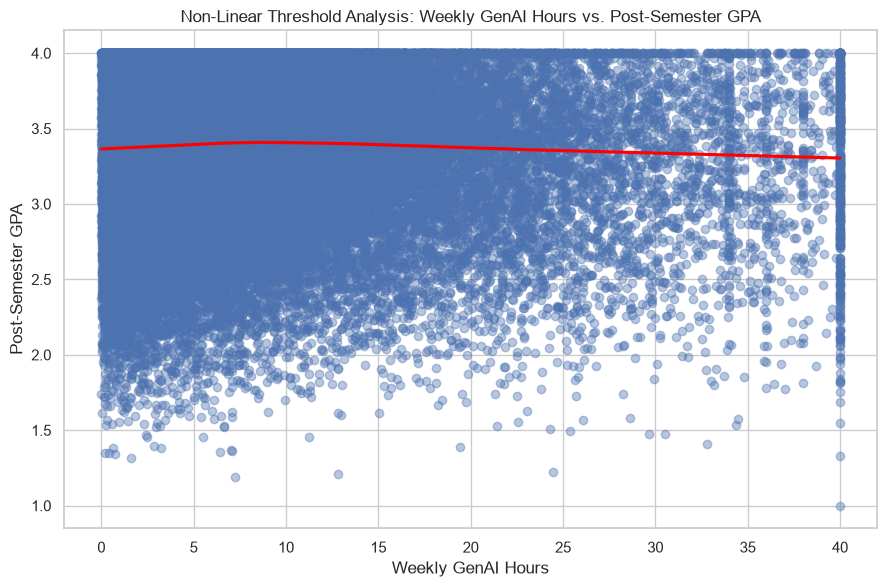

C:\Users\cecil\AppData\Local\Temp\ipykernel_18052\879131302.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


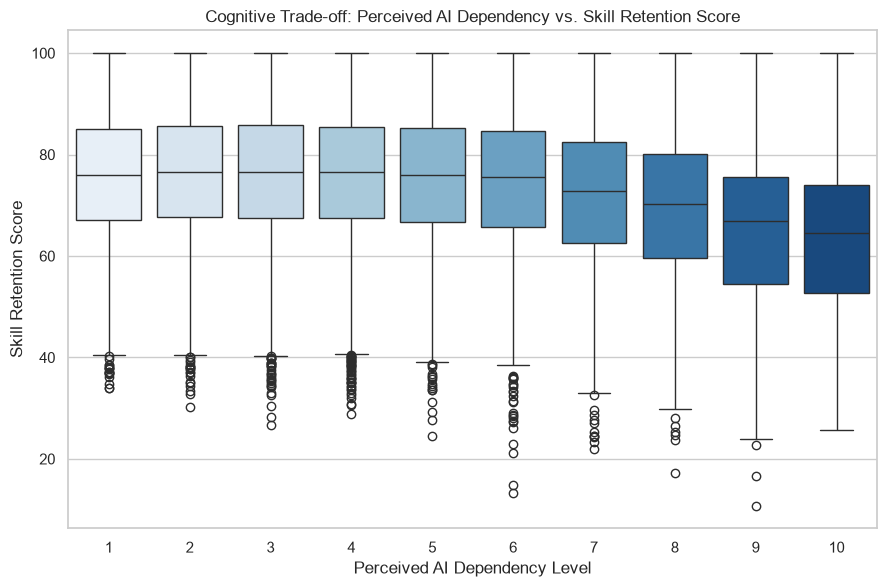

EDA complete and visualization plots saved to disk.


In [35]:
# 4. Non-Linear Relationship / Threshold Analysis (LOESS Curve)
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x="Weekly_GenAI_Hours",
    y="Post_Semester_GPA",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"},
    lowess=True,  # LOESS curve to catch non-linear inflection points ("the cliff")
)
plt.title(
    "Non-Linear Threshold Analysis: Weekly GenAI Hours vs. Post-Semester GPA"
)
plt.xlabel("Weekly GenAI Hours")
plt.ylabel("Post-Semester GPA")
plt.savefig("threshold_analysis_gpa.png", dpi=300)
plt.show()

# 5. Retention Trade-off: Dependency vs Skill Retention
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df, x="Perceived_AI_Dependency", y="Skill_Retention_Score", palette="Blues"
)
plt.title(
    "Cognitive Trade-off: Perceived AI Dependency vs. Skill Retention Score"
)
plt.xlabel("Perceived AI Dependency Level")
plt.ylabel("Skill Retention Score")
plt.savefig("retention_tradeoff.png", dpi=300)
plt.show()

print("EDA complete and visualization plots saved to disk.")

#### Preprocessing, Scaling, and PCA

In [36]:
# 1. Select numerical & ordinal features for our machine learning pipeline
features = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
    "Skill_Retention_Score",
    "Post_Semester_GPA",
]
X = df[features].dropna()

# 2. Standardize features to mean=0, variance=1
# (Critical for both PCA and distance-based clustering like K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply PCA right after scaling
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained Variance by PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Explained Variance by PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total Variance Captured by 2 Components: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Explained Variance by PC1: 32.3%
Explained Variance by PC2: 20.7%
Total Variance Captured by 2 Components: 53.0%


#### Clustering Pipeline with Standardization, K-Means, and Cluster Profiling

K-Means Silhouette Score: 0.145

--- Cluster Behavioral Profiles (Original Units) ---


,Weekly_GenAI_Hours,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Skill_Retention_Score,Post_Semester_GPA
Cluster,,,,,,
0,4.77,14.18,2.51,2.77,80.04,3.60
1,8.19,11.80,3.97,5.97,81.80,3.54
2,5.34,8.47,2.86,3.71,68.74,2.93
3,24.81,8.77,6.41,5.70,68.67,3.27


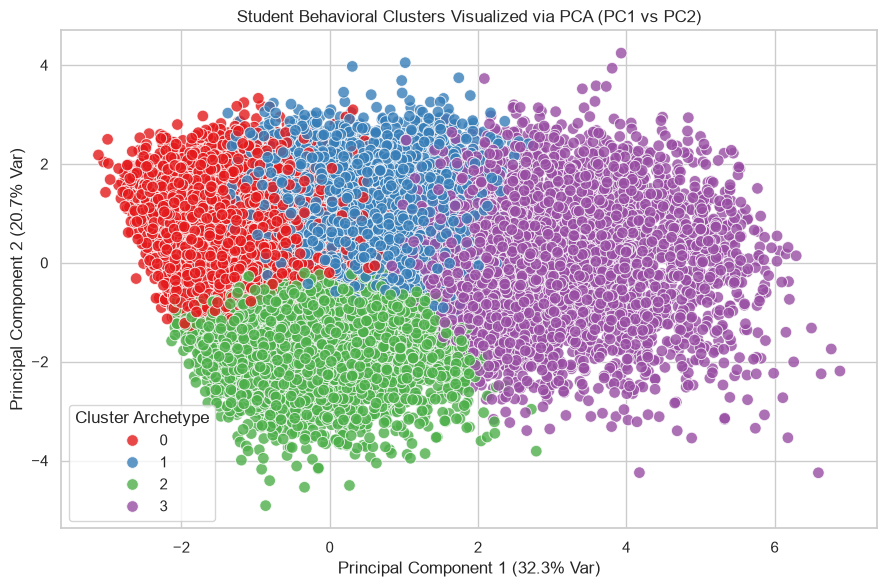


Pipeline complete! Normalization, PCA, Clustering, and Visualizations ready.


In [37]:
# 1. Fit K-Means Clustering on our normalized data (e.g., 4 behavioral archetypes)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_clustered = X.copy()
df_clustered["Cluster"] = kmeans.fit_predict(X_scaled)

# 2. Evaluate cluster separation using Silhouette Score
sil_score = silhouette_score(X_scaled, df_clustered["Cluster"])
print(f"K-Means Silhouette Score: {sil_score:.3f}\n")

# 3. Profile the clusters (Mean values in original units for your report table)
cluster_profile = df_clustered.groupby("Cluster").mean()
print("--- Cluster Behavioral Profiles (Original Units) ---")
display(cluster_profile.round(2))
cluster_profile.to_csv("cluster_profiles_summary.csv")

# 4. Visualize the clusters using the PCA components we calculated in Cell 4
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_clustered["Cluster"],
    palette="Set1",
    s=70,
    alpha=0.8,
)
plt.title("Student Behavioral Clusters Visualized via PCA (PC1 vs PC2)")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Var)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Var)")
plt.legend(title="Cluster Archetype")
plt.savefig("pca_clusters_visualization.png", dpi=300)
plt.show()

print("\nPipeline complete! Normalization, PCA, Clustering, and Visualizations ready.")

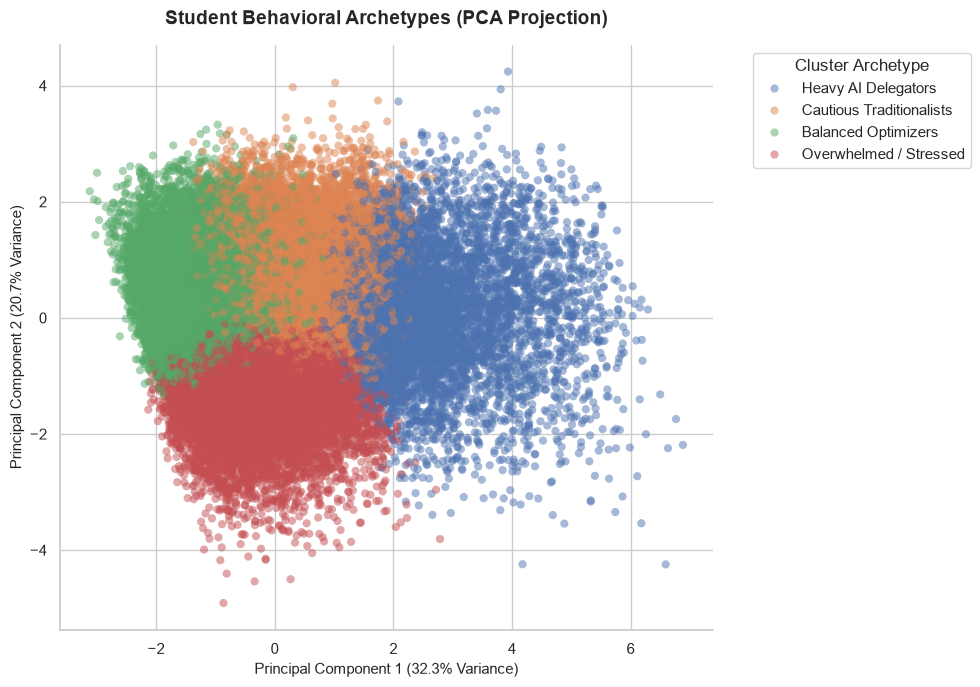


Optimized PCA scatter plot generated and saved as 'pca_clusters_optimized.png'!


In [38]:
# 1. Map cluster numbers to meaningful behavioral names (update names based on your cluster profile table!)
cluster_names = {
    0: "Balanced Optimizers",
    1: "Cautious Traditionalists",
    2: "Overwhelmed / Stressed",
    3: "Heavy AI Delegators",
}
df_clustered["Cluster_Name"] = df_clustered["Cluster"].map(cluster_names)

# 2. Plot with adjusted size and high transparency to fix overplotting
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_clustered["Cluster_Name"],
    palette="deep",  # Clean, professional color palette
    s=35,            # Smaller marker size to prevent solid blocks
    alpha=0.5,       # Higher transparency to reveal data density
    edgecolor="none" # Remove marker borders for a cleaner look
)

# 3. Professional formatting and labels
plt.title("Student Behavioral Archetypes (PCA Projection)", fontsize=14, weight="bold", pad=15)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)", fontsize=11)

# Move legend cleanly outside or in a clear spot
plt.legend(title="Cluster Archetype", bbox_to_anchor=(1.05, 1), loc="upper left", frameon=True)
sns.despine(top=True, right=True) # Remove top and right borders for modern aesthetic

plt.tight_layout()
plt.savefig("pca_clusters_optimized.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nOptimized PCA scatter plot generated and saved as 'pca_clusters_optimized.png'!")

In [45]:
# 4. FREQUENT PATTERN MINING / ASSOCIATION RULES (Chapter 4)
# Discretize continuous columns into categorical bins for Apriori

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

df_assoc = df[num_cols].copy()
df_assoc["GenAI_Usage"] = pd.qcut(
    df_assoc["Weekly_GenAI_Hours"], q=3, labels=["Low_AI", "Med_AI", "High_AI"]
)
df_assoc["Anxiety"] = pd.qcut(
    df_assoc["Anxiety_Level_During_Exams"],
    q=2,
    labels=["Low_Anxiety", "High_Anxiety"],
)
df_assoc["Retention"] = pd.qcut(
    df_assoc["Skill_Retention_Score"], q=2, labels=["Low_Retention", "High_Retention"]
)

basket = pd.get_dummies(
    df_assoc[["GenAI_Usage", "Anxiety", "Retention"]], dtype=bool
)
frequent_itemsets = apriori(basket, min_support=0.15, use_colnames=True)
rules = association_rules(
    frequent_itemsets, metric="lift", min_threshold=1.1
)
print(
    "\nTop Discovered Association Rules:\n",
    rules[["antecedents", "consequents", "support", "confidence", "lift"]],
)


Top Discovered Association Rules:
                          antecedents                        consequents  \
0    frozenset({GenAI_Usage_Low_AI})   frozenset({Anxiety_Low_Anxiety})   
1   frozenset({Anxiety_Low_Anxiety})    frozenset({GenAI_Usage_Low_AI})   
2  frozenset({Anxiety_High_Anxiety})   frozenset({GenAI_Usage_High_AI})   
3   frozenset({GenAI_Usage_High_AI})  frozenset({Anxiety_High_Anxiety})   

   support  confidence      lift  
0  0.21374    0.640170  1.144714  
1  0.21374    0.382197  1.144714  
2  0.18804    0.426627  1.280085  
3  0.18804    0.564210  1.280085  


In [47]:
# Cell 5: Frequent Pattern Mining using Apriori (Adjusted Thresholds)
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Create a working copy for association rules
df_assoc = df[num_cols].copy()

# 2. Discretize features using pd.cut
df_assoc["GenAI_Usage"] = pd.cut(
    df_assoc["Weekly_GenAI_Hours"], 
    bins=3, 
    labels=["Low_AI", "Med_AI", "High_AI"]
)

df_assoc["Anxiety"] = pd.cut(
    df_assoc["Anxiety_Level_During_Exams"],
    bins=2,
    labels=["Low_Anxiety", "High_Anxiety"]
)

df_assoc["Retention"] = pd.cut(
    df_assoc["Skill_Retention_Score"], 
    bins=2, 
    labels=["Low_Retention", "High_Retention"]
)

# 3. One-hot encode into boolean columns
basket = pd.get_dummies(
    df_assoc[["GenAI_Usage", "Anxiety", "Retention"]], 
    dtype=bool
)

# 4. LOWERED THRESHOLDS: min_support=0.03 (3%), min_threshold=1.0
frequent_itemsets = apriori(basket, min_support=0.03, use_colnames=True)
rules = association_rules(
    frequent_itemsets, metric="lift", min_threshold=1.0
)

print(f"Total Association Rules Found: {len(rules)}")

if len(rules) > 0:
    print("\nTop Discovered Association Rules:")
    display(
        rules[["antecedents", "consequents", "support", "confidence", "lift"]]
        .sort_values(by="lift", ascending=False)
        .head()
    )
else:
    print("Still 0 rules? Let's check your frequent itemsets table:")
    display(frequent_itemsets)

Total Association Rules Found: 22

Top Discovered Association Rules:


,antecedents,consequents,support,confidence,lift
5,frozenset({GenAI_Usage_Med_AI}),frozenset({Anxiety_High_Anxiety}),0.0658,0.414462,1.499935
4,frozenset({Anxiety_High_Anxiety}),frozenset({GenAI_Usage_Med_AI}),0.0658,0.238130,1.499935
21,frozenset({GenAI_Usage_Med_AI}),"frozenset({Anxiety_High_Anxiety, Retention_Hig...",0.0605,0.381078,1.497714
18,"frozenset({Anxiety_High_Anxiety, Retention_Hig...",frozenset({GenAI_Usage_Med_AI}),0.0605,0.237777,1.497714
20,frozenset({Anxiety_High_Anxiety}),"frozenset({Retention_High_Retention, GenAI_Usa...",0.0605,0.218949,1.489247


#### Nested Cross-Validation with Random Forest and Hyperparameter Tuning

   -> Fold 1 Accuracy: 45.84% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}
   -> Fold 2 Accuracy: 45.47% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}
   -> Fold 3 Accuracy: 44.68% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 150}
   -> Fold 4 Accuracy: 44.72% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}
   -> Fold 5 Accuracy: 44.52% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}

Nested CV Average Accuracy: 45.05% (+/- 0.52%)


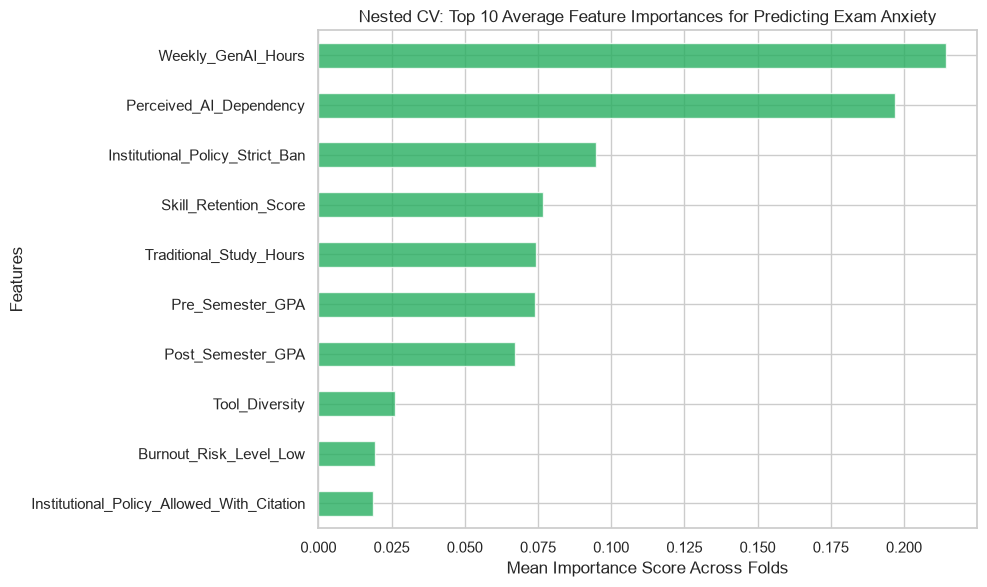


Nested cross-validation pipeline complete


In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define Target Variable: 3 Anxiety Classes (0 = Low, 1 = Medium, 2 = High)
df["Target_Anxiety_Class"] = pd.qcut(
    df["Anxiety_Level_During_Exams"], 
    q=3, 
    labels=[0, 1, 2]
)

# 2. Drop leakage columns, identifiers, and target variables safely
drop_cols = [
    "Student_ID", 
    "Anxiety_Level_During_Exams", 
    "Target_Anxiety_Class", 
    "Target_High_Anxiety"
]
X_raw = df.drop(columns=drop_cols, errors="ignore")
y_class = df["Target_Anxiety_Class"].astype(int)

# 3. One-hot encode all categorical columns
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# 4. Setup Nested Cross-Validation Structure
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Hyperparameter grid for the inner loop optimization
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

outer_scores = []
feature_importances_list = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X_encoded, y_class)):
    X_train, X_test = X_encoded.iloc[train_idx], X_encoded.iloc[test_idx]
    y_train, y_test = y_class.iloc[train_idx], y_class.iloc[test_idx]
    
    # Inner loop: Grid Search for hyperparameter tuning
    rf = RandomForestClassifier(random_state=42)
    clf = GridSearchCV(estimator=rf, param_grid=param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1)
    
    # Fit model (hyperparameter optimization happens entirely inside the inner folds)
    clf.fit(X_train, y_train)
    
    # Evaluate model on the unseen outer test fold
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    outer_scores.append(acc)
    
    # Save the feature importances from this fold's best estimator
    feature_importances_list.append(clf.best_estimator_.feature_importances_)
    
    print(f"   -> Fold {fold+1} Accuracy: {acc*100:.2f}% | Best Hyperparameters: {clf.best_params_}")

# 5. Summary Results
mean_acc = np.mean(outer_scores) * 100
std_acc = np.std(outer_scores) * 100
print(f"\nNested CV Average Accuracy: {mean_acc:.2f}% (+/- {std_acc:.2f}%)")

# 6. Average Feature Importances across all outer folds
mean_importances = pd.Series(np.mean(feature_importances_list, axis=0), index=X_encoded.columns)

plt.figure(figsize=(10, 6))
mean_importances.nlargest(10).sort_values().plot(kind="barh", color="#27ae60", alpha=0.8)
plt.title("Nested CV: Top 10 Average Feature Importances for Predicting Exam Anxiety")
plt.xlabel("Mean Importance Score Across Folds")
plt.ylabel("Features")
plt.savefig("random_forest_nested_cv_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nNested cross-validation pipeline complete")